# Importando Bibliotecas

In [1]:
import os
import logging

try:
    # Configurando diretório de trabalho para 'aulas_teoricas'
    os.chdir("aulas_teoricas")
except FileNotFoundError:
    pass
# 1. Silencia avisos da camada nativa (C++) do TensorFlow e subprocessos Python
# 0 = todos os logs, 1 = oculta INFO, 2 = oculta INFO e WARNING, 3 = oculta tudo (até ERROR do C++)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["PYTHONWARNINGS"] = "ignore"

# 2. Silencia avisos nativos do Python
import warnings

warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

# 3. Silencia loggers do TensorFlow e Keras (deve vir logo após importar o TF)
import tensorflow as tf

tf.get_logger().setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)
logging.getLogger("tensorflow").setLevel(logging.ERROR)

In [16]:
os.chdir('df_resultados_Sofia')

In [17]:
os.listdir()

['df_classifiedk-NN',
 'df_classified_GBM',
 'df_classified_NB',
 'df_classified_NN',
 'df_classified_RF',
 'df_classified_SVM',
 'df_metricasCD34_log_Lin_B',
 'df_metricasCD34_log_Lin_T',
 'df_metricasLin_B_CD34_log',
 'df_metricasLin_B_Lin_T',
 'df_metricasLin_T_CD34_log',
 'df_metricasLin_T_Lin_B',
 'df_metricas_repetiCD34_log_Lin_B_kmeans',
 'df_metricas_repeti_trainCD34_log_Lin_B_agg',
 'df_metricas_repeti_treino_CD34_log_Lin_B_dbscan',
 'df_metricas_repeti_treino_CD43_log_Lin_B_dbscan',
 'df_metricas_repeti_validCD34_log_LinB_dbscan',
 'df_metricas_repeti_validCD34_log_LinB_kmeans',
 'df_metricas_repeti_validCD34_log_Lin_B_agg',
 'df_test_predicoes_classificacao',
 'df_trabalho_X_test',
 'df_trabalho_X_train',
 'df_trabalho_X_valid',
 'df_trabalho_y_test',
 'df_trabalho_y_train',
 'df_trabalho_y_valid',
 'df_train_predicoes_classificacao',
 'df_valid_predicoes_classificacao']

In [3]:
# Carregamento de dados
from joblib import load, dump

# Processamento de dados
import pandas as pd
import numpy as np

# Estatística
from scipy.stats import chi2_contingency
from scipy.stats import ks_2samp
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu
from scipy.stats import levene

# Graficos
import seaborn as sns
import matplotlib.pyplot as plt

# Classificador
from src.regression import Regression

In [4]:
import numpy as np

# Importando Dados

In [18]:
# Importando os dados de treino
df_train = pd.concat(
    [
        load("./df_trabalho_X_train"),
        load("./df_trabalho_y_train"),
    ],
    axis=1,
)
df_train.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
541,-6.605859,587.422573,861.125119,1.728509,1,0,0,1,0,1,imunodeficiencia
440,-4.329437,500.185650,801.998581,1.240507,1,0,0,1,0,1,imunodeficiencia
482,-1.748794,208.645029,1299.553614,1.470395,0,1,1,0,0,1,leucemia
422,-4.197952,537.954188,889.391214,1.574182,1,0,0,1,0,1,imunodeficiencia
778,-1.880539,274.394770,1419.982269,3.714128,0,1,1,0,0,1,leucemia


In [19]:
# Importando os dados de treino
df_valid = pd.concat(
    [
        load("./df_trabalho_X_valid"),
        load("./df_trabalho_y_valid"),
    ],
    axis=1,
)
df_valid.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
904,-4.354233,683.860757,702.521323,2.228345,1,0,0,1,0,1,imunodeficiencia
543,-1.963294,237.586357,1456.448090,2.271285,0,1,1,0,0,1,leucemia
139,-2.771307,223.769444,1315.554814,0.532531,0,1,1,0,0,1,cancer
526,-1.810700,364.827049,1268.215382,1.394407,0,1,1,0,0,1,cancer
868,-2.473679,271.804503,1187.576700,0.468055,0,1,1,0,0,1,cancer


In [23]:
# Importando os dados de teste
df_test = pd.concat(
    [
        load("./df_trabalho_X_test"),
        load("./df_trabalho_y_test"),
    ],
    axis=1,
)
df_test.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
557,-3.243291,343.587918,1092.448432,1.478703,0,1,1,0,0,1,cancer
798,-2.082097,308.565265,1514.927999,1.406982,0,1,1,0,0,1,leucemia
977,-2.154434,208.457031,1317.570437,2.114693,0,1,1,0,0,1,cancer
136,-2.780156,279.316121,1304.394062,1.050797,0,1,1,0,0,1,cancer
575,-4.625737,547.067973,802.296876,2.145163,1,0,0,1,0,1,imunodeficiencia


# Validação cruzada e busca de hiperparâmetros

In [20]:
df_train = df_train[['CD34_log', 'Lin_B', 'Lin_T', 'PPD_log']]

In [21]:
df_valid= df_valid[['CD34_log', 'Lin_B', 'Lin_T', 'PPD_log']]

In [24]:
df_test = df_test[['CD34_log', 'Lin_B', 'Lin_T', 'PPD_log']]

In [25]:
df_test

,CD34_log,Lin_B,Lin_T,PPD_log
557,-3.243291,343.587918,1092.448432,1.478703
798,-2.082097,308.565265,1514.927999,1.406982
977,-2.154434,208.457031,1317.570437,2.114693
136,-2.780156,279.316121,1304.394062,1.050797
575,-4.625737,547.067973,802.296876,2.145163
...,...,...,...,...
280,-4.276645,207.050619,1412.865623,3.714128
677,-1.739342,312.692349,1466.827903,2.057824
244,-4.969496,223.835913,1744.066111,4.440158
523,-2.882618,314.600870,1095.017281,1.156679


## Treino

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_T

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True               True
            num__Lin_B              True              False
            num__Lin_T              True               True


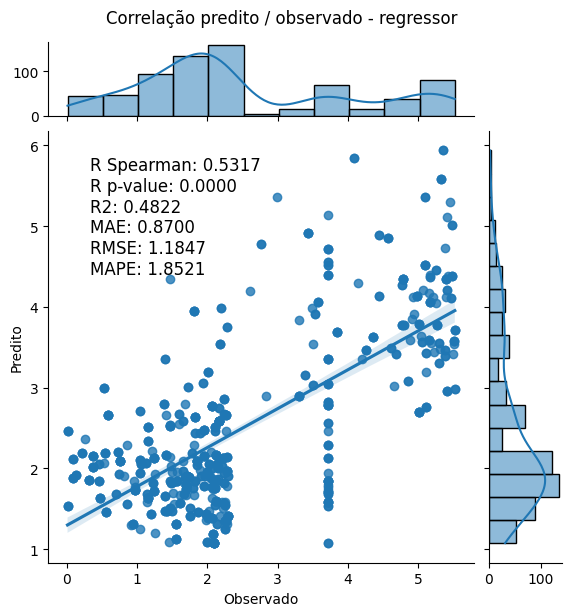

In [26]:
regressor = Regression(df=df_train)

metricas_regr, pred_regr = regressor.regress(modelo="regressor")


Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> all
svm__C -> 10
svm__epsilon -> 0.2
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    3

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True               True
            num__Lin_B              True               True
            num__Lin_T              True               True


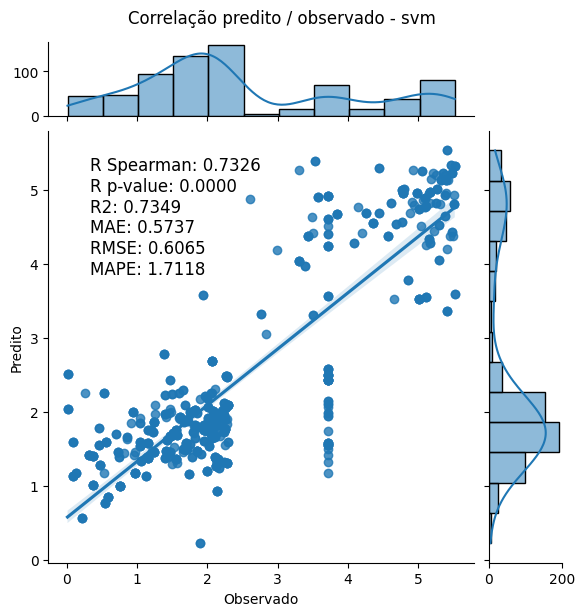

In [27]:
metricas_svm, pred_svm = regressor.regress(modelo="svm")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_T

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True               True
            num__Lin_B              True              False
            num__Lin_T              True               True


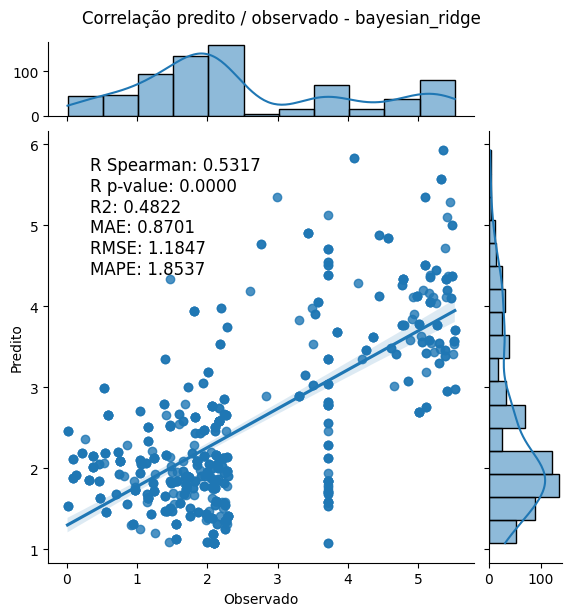

In [28]:
metricas_nb, pred_nb = regressor.regress(modelo="bayesian_ridge")

O cálculo do volume de treinos atual é:$$\underbrace{3}_{\text{threshold}} \times \underbrace{3}_{\text{k}} \times \underbrace{3}_{\text{optimizer}} \times \underbrace{2}_{\text{epochs}} \times \underbrace{3}_{\text{batch\_size}} \times \underbrace{4}_{\text{activation1}} \times \underbrace{4}_{\text{activation2}} = 2.592 \text{ combinações}$$Multiplicado pelos $5$ folds do Cross-Validation: $2.592 \times 5 = 12.960$ modelos sendo ajustados.

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.05
nn__optimizer -> Adam
nn__epochs -> 100
nn__batch_size -> 16
nn__activation2 -> softmax
nn__activation1 -> tanh
feature_selection__k -> 2
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_T

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True               True
            num__Lin_B              True              False
            num__Lin_T              True               True


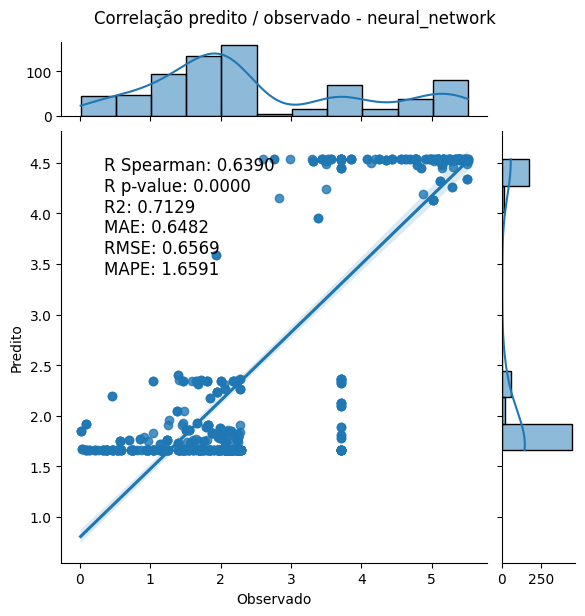

In [29]:
metricas_nn, pred_nn = regressor.regress(modelo="neural_network", n_iter_search=1)

In [30]:
try:
    metricas_estr, pred_estr = regressor.regress(modelo="Estrela")
except ValueError as e:
    print(e)

Modelo inválido: Estrela. Escolha 'regressor', 'svm', 'bayesian_ridge' ou 'neural_network'.


In [31]:
algoritmo_1 = "Multiple Linear Regression"
algoritmo_2 = "Suport Vector Machine"
algoritmo_3 = "Nayve Bayes"
algoritmo_4 = "Neural Network"

# Organizando as métricas de treinamento
df_metricas_train = pd.concat(
    [
        metricas_regr.T.copy(),
        metricas_svm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_train.reset_index(inplace=True)
df_metricas_train["modelo"] = (
    [algoritmo_1] * 6 + [algoritmo_2] * 6 + [algoritmo_3] * 6 +  [algoritmo_4] * 6
)
df_metricas_train.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_train.head()

,metricas,valores,modelo
0,R Spearman,0.5317,Multiple Linear Regression
1,R p-value,0.0000,Multiple Linear Regression
2,R2,0.4822,Multiple Linear Regression
3,MAE,0.8700,Multiple Linear Regression
4,RMSE,1.1847,Multiple Linear Regression


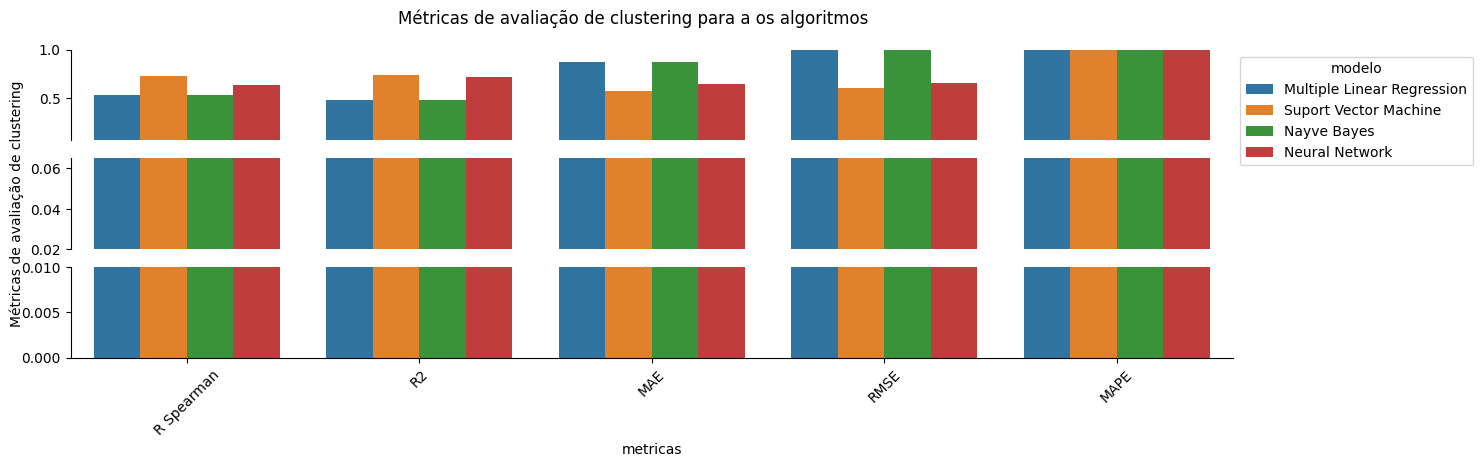

In [32]:
# Grafico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas
fig, ax = plt.subplots(3, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a os algoritmos")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_train[df_metricas_train["metricas"] != "R p-value"],
    ax=ax[0],
)
p.set_ylim(0.065, 1)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
sns.move_legend(ax[0], "upper left", bbox_to_anchor=(1, 1))
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

t = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_train[df_metricas_train["metricas"] != "R p-value"],
    ax=ax[1],
)
t.set_ylim(0.02, 0.065)
t.set(xlabel=None)
t.set_xticks([])
t.spines["bottom"].set_visible(False)
t.spines[["top", "right"]].set_visible(False)
t.get_legend().remove()
t.set_ylabel("Métricas de avaliação de clustering", loc="center")

q = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_train[df_metricas_train["metricas"] != "R p-value"],
    ax=ax[2],
)
q.set(ylabel=None)
q.set_ylim(0, 0.01)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45)

plt.show()

In [33]:
df_train[algoritmo_1] = pred_regr.copy()
df_train[algoritmo_2] = pred_svm.copy()
df_train[algoritmo_3] = pred_nb.copy()
df_train[algoritmo_4] = pred_nn.copy()

df_train.head()

,CD34_log,Lin_B,Lin_T,PPD_log,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
541,-6.605859,587.422573,861.125119,1.728509,3.007081,1.878193,3.005528,2.352702
440,-4.329437,500.185650,801.998581,1.240507,1.721361,1.861526,1.723758,1.760985
482,-1.748794,208.645029,1299.553614,1.470395,1.514230,1.677111,1.517248,1.658626
422,-4.197952,537.954188,889.391214,1.574182,1.848215,1.684259,1.850220,1.726162
778,-1.880539,274.394770,1419.982269,3.714128,1.847781,1.548186,1.849771,1.658626


In [34]:
dump(df_train, 'df_train_predicoes_regressao')

['df_train_predicoes_regressao']

## Validação

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_T

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True               True
            num__Lin_B              True              False
            num__Lin_T              True               True


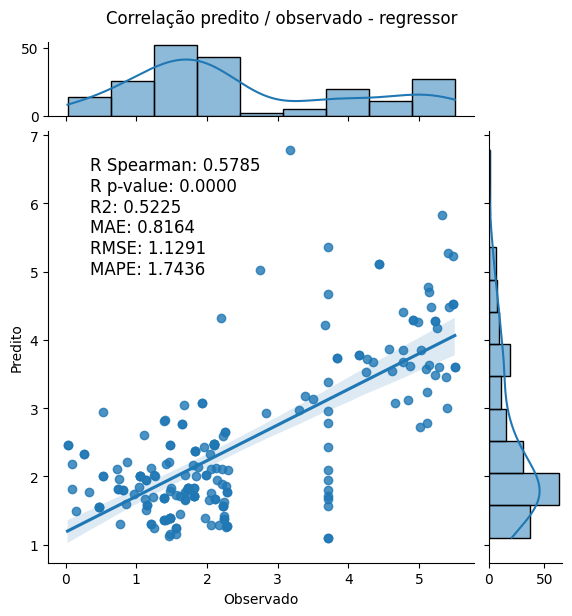

In [35]:
regressor = Regression(df=df_valid)

metricas_regr, pred_regr = regressor.regress(modelo="regressor")

Iniciando o Grid Search com Cross Validation...


Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
svm__C -> 1
svm__epsilon -> 0.01
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_T

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True               True
            num__Lin_B              True              False
            num__Lin_T              True               True


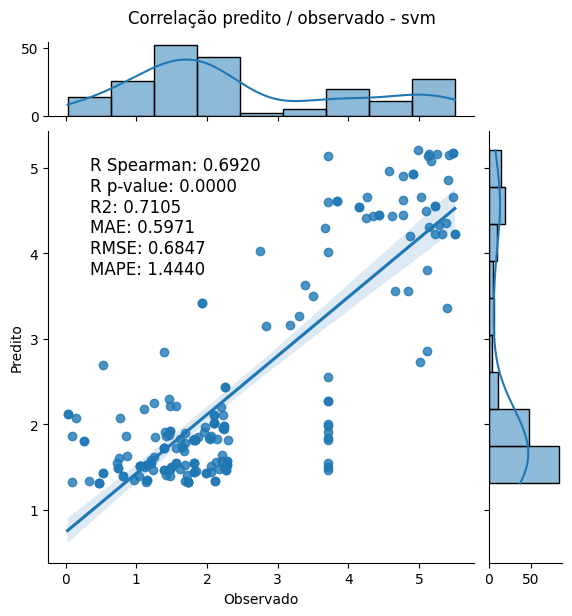

In [36]:
metricas_svm, pred_svm = regressor.regress(modelo="svm")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_T

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True               True
            num__Lin_B              True              False
            num__Lin_T              True               True


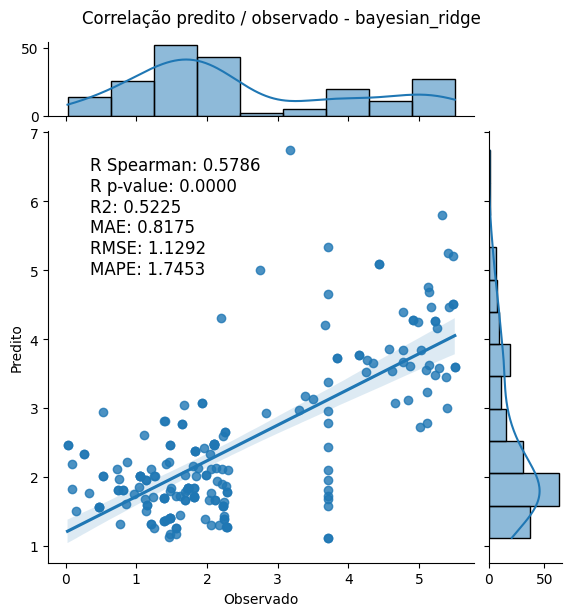

In [37]:
metricas_nb, pred_nb = regressor.regress(modelo="bayesian_ridge")

O cálculo do volume de treinos atual é:$$\underbrace{3}_{\text{threshold}} \times \underbrace{3}_{\text{k}} \times \underbrace{3}_{\text{optimizer}} \times \underbrace{2}_{\text{epochs}} \times \underbrace{3}_{\text{batch\_size}} \times \underbrace{4}_{\text{activation1}} \times \underbrace{4}_{\text{activation2}} = 2.592 \text{ combinações}$$Multiplicado pelos $5$ folds do Cross-Validation: $2.592 \times 5 = 12.960$ modelos sendo ajustados.

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.01
nn__optimizer -> SGD
nn__epochs -> 100
nn__batch_size -> 32
nn__activation2 -> tanh
nn__activation1 -> tanh
feature_selection__k -> 1
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    1

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True               True
            num__Lin_B              True              False
            num__Lin_T              True              False


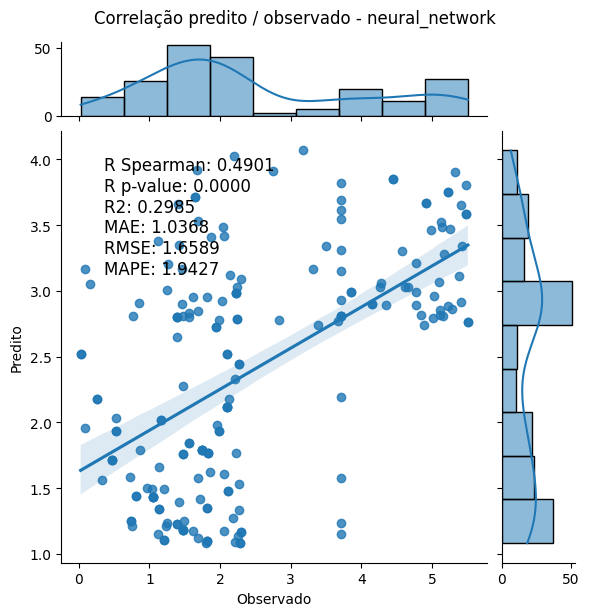

In [38]:
metricas_nn, pred_nn = regressor.regress(modelo="neural_network", n_iter_search=2)

In [39]:
try:
    metricas_estr, pred_estr = regressor.regress(modelo="Estrela")
except ValueError as e:
    print(e)

Modelo inválido: Estrela. Escolha 'regressor', 'svm', 'bayesian_ridge' ou 'neural_network'.


In [40]:
# Organizando as métricas de treinamento
df_metricas_valid = pd.concat(
    [
        metricas_regr.T.copy(),
        metricas_svm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_valid.reset_index(inplace=True)
df_metricas_valid["modelo"] = (
    [algoritmo_1] * 6 + [algoritmo_2] * 6 + [algoritmo_3] * 6 +[algoritmo_4] * 6
)
df_metricas_valid.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_valid.head()

,metricas,valores,modelo
0,R Spearman,0.5785,Multiple Linear Regression
1,R p-value,0.0000,Multiple Linear Regression
2,R2,0.5225,Multiple Linear Regression
3,MAE,0.8164,Multiple Linear Regression
4,RMSE,1.1291,Multiple Linear Regression


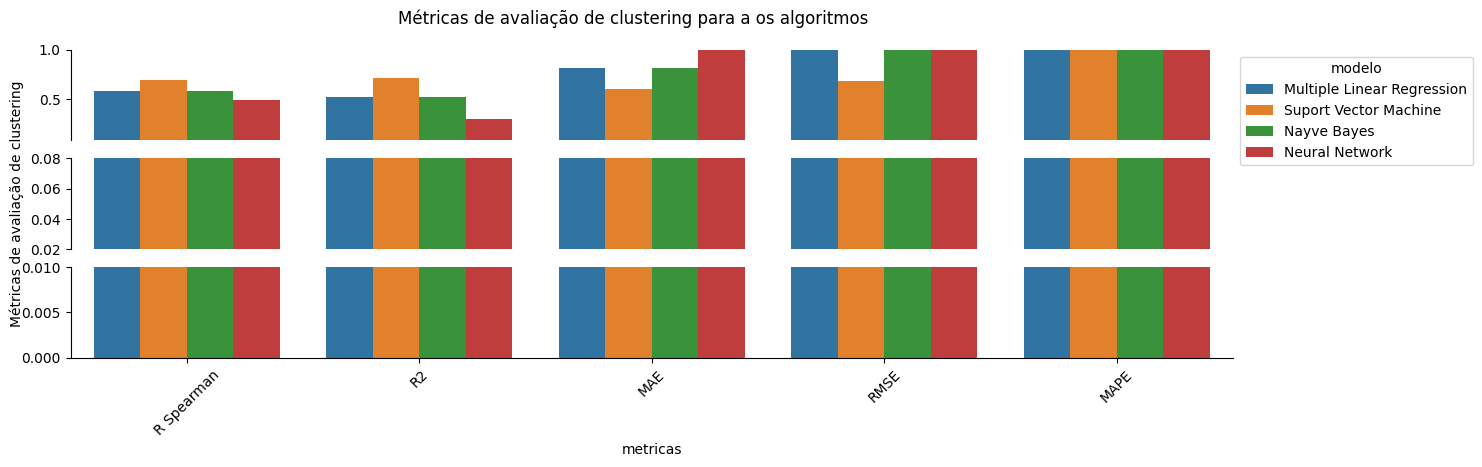

In [41]:
# Grafico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas
fig, ax = plt.subplots(3, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a os algoritmos")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid[df_metricas_valid["metricas"] != "R p-value"],
    ax=ax[0],
)
p.set_ylim(0.08, 1)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
sns.move_legend(ax[0], "upper left", bbox_to_anchor=(1, 1))
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

t = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid[df_metricas_valid["metricas"] != "R p-value"],
    ax=ax[1],
)
t.set_ylim(0.02, 0.08)
t.set(xlabel=None)
t.set_xticks([])
t.spines["bottom"].set_visible(False)
t.spines[["top", "right"]].set_visible(False)
t.get_legend().remove()
t.set_ylabel("Métricas de avaliação de clustering", loc="center")

q = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid[df_metricas_valid["metricas"] != "R p-value"],
    ax=ax[2],
)
q.set(ylabel=None)
q.set_ylim(0, 0.01)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45)

plt.show()

In [42]:
df_valid[algoritmo_1] = pred_regr.copy()
df_valid[algoritmo_2] = pred_svm.copy()
df_valid[algoritmo_3] = pred_nb.copy()
df_valid[algoritmo_4] = pred_nn.copy()

df_valid.head()

,CD34_log,Lin_B,Lin_T,PPD_log,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
904,-4.354233,683.860757,702.521323,2.228345,1.562773,1.959288,1.571552,2.982187
543,-1.963294,237.586357,1456.448090,2.271285,1.859920,1.467933,1.865499,1.336265
139,-2.771307,223.769444,1315.554814,0.532531,2.012358,1.427517,2.016639,1.936241
526,-1.810700,364.827049,1268.215382,1.394407,1.354163,1.469364,1.364476,1.225031
868,-2.473679,271.804503,1187.576700,0.468055,1.556866,1.308702,1.565383,1.715038


In [43]:
dump(df_valid, 'df_valid_predicoes_regressao')

['df_valid_predicoes_regressao']

## Teste

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
regressor__fit_intercept -> True
regressor__positive -> False
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_T

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True               True
            num__Lin_B              True              False
            num__Lin_T              True               True


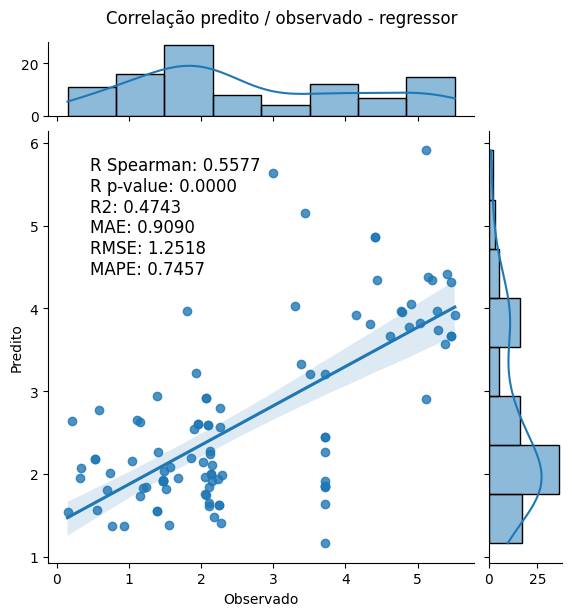

In [44]:
regressor = Regression(df=df_test)

metricas_regr, pred_regr = regressor.regress(modelo="regressor")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
svm__C -> 10
svm__epsilon -> 0.01
svm__kernel -> rbf
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_T

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True               True
            num__Lin_B              True              False
            num__Lin_T              True               True


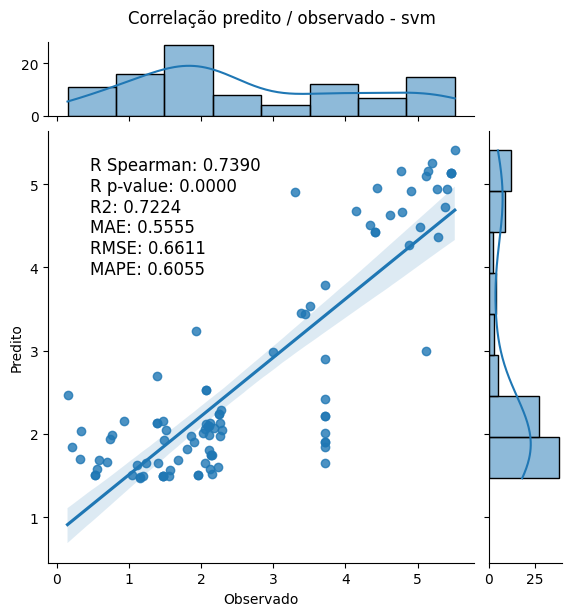

In [45]:
metricas_svm, pred_svm = regressor.regress(modelo="svm")

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
feature_selection__k -> 2
nb__alpha_1 -> 0.0001
nb__lambda_1 -> 1e-06
nb__max_iter -> 100
var_threshold__threshold -> 0.0001
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_T

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True               True
            num__Lin_B              True              False
            num__Lin_T              True               True


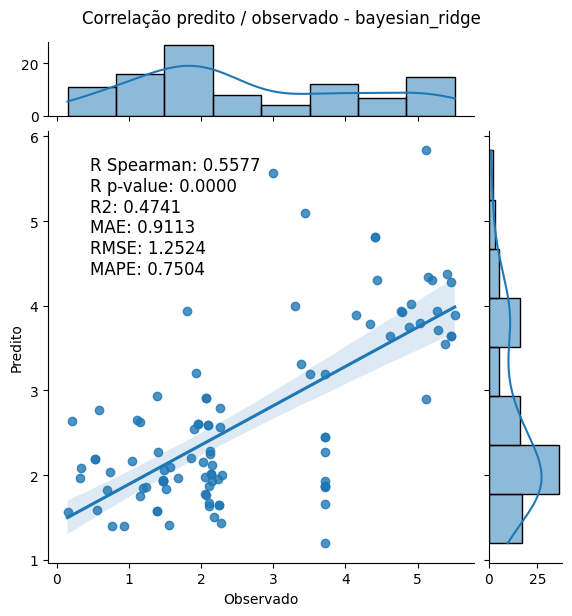

In [46]:
metricas_nb, pred_nb = regressor.regress(modelo="bayesian_ridge")

O cálculo do volume de treinos atual é:$$\underbrace{3}_{\text{threshold}} \times \underbrace{3}_{\text{k}} \times \underbrace{3}_{\text{optimizer}} \times \underbrace{2}_{\text{epochs}} \times \underbrace{3}_{\text{batch\_size}} \times \underbrace{4}_{\text{activation1}} \times \underbrace{4}_{\text{activation2}} = 2.592 \text{ combinações}$$Multiplicado pelos $5$ folds do Cross-Validation: $2.592 \times 5 = 12.960$ modelos sendo ajustados.

Iniciando o Grid Search com Cross Validation...
Grid Search concluído.
Melhores parâmetros encontrados:
------------------
-=< Dicionário >=-
------------------
var_threshold__threshold -> 0.01
nn__optimizer -> SGD
nn__epochs -> 10
nn__batch_size -> 16
nn__activation2 -> sigmoid
nn__activation1 -> tanh
feature_selection__k -> 1
Total de variáveis originais pré-processadas: 3
Total de variáveis após VarianceThreshold:    3
Total de variáveis selecionadas no modelo:    1

--- Lista das Variáveis Selecionadas ---
1. num__Lin_T

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log              True              False
            num__Lin_B              True              False
            num__Lin_T              True               True


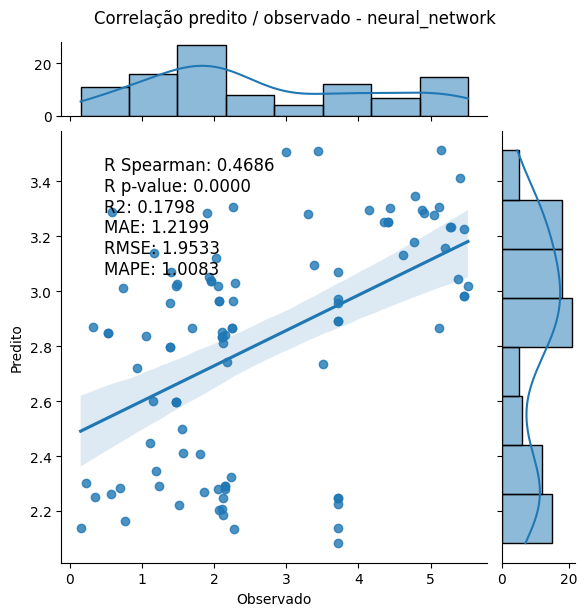

In [47]:
metricas_nn, pred_nn = regressor.regress(modelo="neural_network", n_iter_search=1)

In [48]:
# Organizando as métricas de treinamento
df_metricas_test = pd.concat(
    [
        metricas_regr.T.copy(),
        metricas_svm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_test.reset_index(inplace=True)
df_metricas_test["modelo"] = (
    [algoritmo_1] * 6 + [algoritmo_2] * 6 + [algoritmo_3] * 6 + [algoritmo_4] * 6
)
df_metricas_test.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_test.head()

,metricas,valores,modelo
0,R Spearman,0.5577,Multiple Linear Regression
1,R p-value,0.0000,Multiple Linear Regression
2,R2,0.4743,Multiple Linear Regression
3,MAE,0.9090,Multiple Linear Regression
4,RMSE,1.2518,Multiple Linear Regression


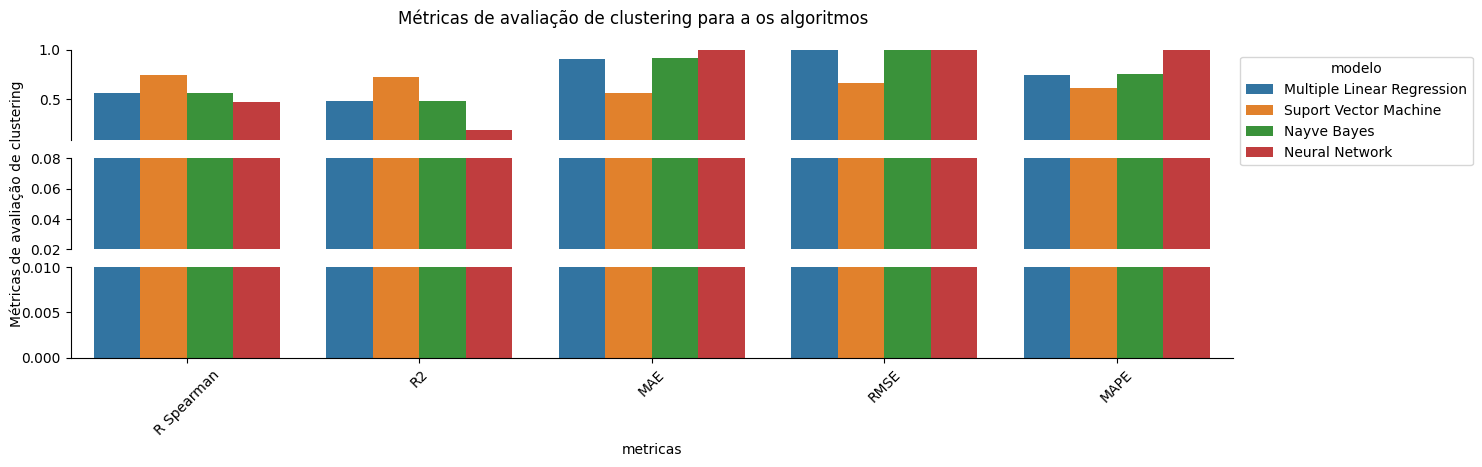

In [49]:
# Grafico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas
fig, ax = plt.subplots(3, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a os algoritmos")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test[df_metricas_test["metricas"] != "R p-value"],
    ax=ax[0],
)
p.set_ylim(0.08, 1)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
sns.move_legend(ax[0], "upper left", bbox_to_anchor=(1, 1))
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

t = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test[df_metricas_test["metricas"] != "R p-value"],
    ax=ax[1],
)
t.set_ylim(0.02, 0.08)
t.set(xlabel=None)
t.set_xticks([])
t.spines["bottom"].set_visible(False)
t.spines[["top", "right"]].set_visible(False)
t.get_legend().remove()
t.set_ylabel("Métricas de avaliação de clustering", loc="center")

q = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test[df_metricas_test["metricas"] != "R p-value"],
    ax=ax[2],
)
q.set(ylabel=None)
q.set_ylim(0, 0.01)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45)

plt.show()

In [50]:
df_test[algoritmo_1] = pred_regr.copy()
df_test[algoritmo_2] = pred_svm.copy()
df_test[algoritmo_3] = pred_nb.copy()
df_test[algoritmo_4] = pred_nn.copy()

df_test.head()

,CD34_log,Lin_B,Lin_T,PPD_log,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
557,-3.243291,343.587918,1092.448432,1.478703,1.917833,1.488709,1.934685,2.598279
798,-2.082097,308.565265,1514.927999,1.406982,2.260145,1.653333,2.269855,3.069576
977,-2.154434,208.457031,1317.570437,2.114693,1.846367,1.802196,1.865291,2.851518
136,-2.780156,279.316121,1304.394062,1.050797,2.154042,1.504738,2.165818,2.836670
575,-4.625737,547.067973,802.296876,2.145163,1.998634,1.747107,2.013077,2.292199


In [51]:
dump(df_test, 'df_test_predicoes_regressao')

['df_test_predicoes_regressao']

# Avalia Modelos

In [ ]:
df_train = load("./data/df_resultados_Sofia/df_train_predicoes_regressao")

df_valid = load("./data/df_resultados_Sofia/df_valid_predicoes_regressao")

df_test = load("./data/df_resultados_Sofia/df_test_predicoes_regressao")

In [54]:
df_train.head()

,CD34_log,Lin_B,Lin_T,PPD_log,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
541,-6.605859,587.422573,861.125119,1.728509,3.007081,1.878193,3.005528,2.352702
440,-4.329437,500.185650,801.998581,1.240507,1.721361,1.861526,1.723758,1.760985
482,-1.748794,208.645029,1299.553614,1.470395,1.514230,1.677111,1.517248,1.658626
422,-4.197952,537.954188,889.391214,1.574182,1.848215,1.684259,1.850220,1.726162
778,-1.880539,274.394770,1419.982269,3.714128,1.847781,1.548186,1.849771,1.658626


In [55]:
df_valid.head()

,CD34_log,Lin_B,Lin_T,PPD_log,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
904,-4.354233,683.860757,702.521323,2.228345,1.562773,1.959288,1.571552,2.982187
543,-1.963294,237.586357,1456.448090,2.271285,1.859920,1.467933,1.865499,1.336265
139,-2.771307,223.769444,1315.554814,0.532531,2.012358,1.427517,2.016639,1.936241
526,-1.810700,364.827049,1268.215382,1.394407,1.354163,1.469364,1.364476,1.225031
868,-2.473679,271.804503,1187.576700,0.468055,1.556866,1.308702,1.565383,1.715038


In [56]:
df_test.head()

,CD34_log,Lin_B,Lin_T,PPD_log,Multiple Linear Regression,Suport Vector Machine,Nayve Bayes,Neural Network
557,-3.243291,343.587918,1092.448432,1.478703,1.917833,1.488709,1.934685,2.598279
798,-2.082097,308.565265,1514.927999,1.406982,2.260145,1.653333,2.269855,3.069576
977,-2.154434,208.457031,1317.570437,2.114693,1.846367,1.802196,1.865291,2.851518
136,-2.780156,279.316121,1304.394062,1.050797,2.154042,1.504738,2.165818,2.836670
575,-4.625737,547.067973,802.296876,2.145163,1.998634,1.747107,2.013077,2.292199


In [57]:
def testar_hipotese(y_pred_treino: pd.Series, y_pred_teste: pd.Series) -> None:
    """
    Testa a hipótese de que a distribuição das classes no treino e no teste é estatisticamente igual (homogênea)
    ou diferente (heterogênea) usando o teste Qui-Quadrado.

    Parâmetros:
        y_pred_treino : pd.Series
            Série contendo as previsões do conjunto de treino.
        y_pred_teste : pd.Series
            Série contendo as previsões do conjunto de teste.
    Retorna:
        None
    """

    ks_stat, p_v_ks = ks_2samp(y_pred_treino, y_pred_teste)

    # 1. Teste T de Welch (para médias, assumindo variâncias potencialmente diferentes)
    t_stat, p_val_t = ttest_ind(y_pred_treino, y_pred_teste, equal_var=False)

    # 2. Teste U de Mann-Whitney (para medianas/posição, não-paramétrico)
    u_stat, p_val_u = mannwhitneyu(y_pred_treino, y_pred_teste, alternative="two-sided")

    # 3. Teste de Levene (para variâncias/dispersão)
    w_stat, p_val_levene = levene(y_pred_treino, y_pred_teste)

    # Função auxiliar para imprimir resultados
    def interpretar(nome_teste, p_valor, stat, alfa=0.05):
        resultado = (
            "DIFERENTES (Rejeita H0)"
            if p_valor < alfa
            else "IGUAIS (Falha ao rejeitar H0)"
        )
        print(
            f"{nome_teste:<25} | estatística: {stat:.4f} | p-valor: {p_valor:.4f} | Conclusão: {resultado}"
        )

    print("=== Resultados dos Testes Estatísticos ===\n")
    interpretar("Teste Kolmogorov-Smirnov", p_v_ks, ks_stat)
    interpretar("Teste T (Médias)", p_val_t, t_stat)
    interpretar("Mann-Whitney (Medianas)", p_val_u, u_stat)
    interpretar("Levene (Variâncias)", p_val_levene, w_stat)

    return None

In [58]:
c = -4
print(f"\n\nTestando a hipótese para o modelo: {df_train.columns[c]}")

testar_hipotese(
    y_pred_treino=df_train[df_train.columns[c]],
    y_pred_teste=df_test[df_test.columns[c]],
)



Testando a hipótese para o modelo: Multiple Linear Regression
=== Resultados dos Testes Estatísticos ===

Teste Kolmogorov-Smirnov  | estatística: 0.1157 | p-valor: 0.1811 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Teste T (Médias)          | estatística: -1.4406 | p-valor: 0.1522 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Mann-Whitney (Medianas)   | estatística: 31284.0000 | p-valor: 0.0856 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Levene (Variâncias)       | estatística: 0.1748 | p-valor: 0.6760 | Conclusão: IGUAIS (Falha ao rejeitar H0)


In [59]:
c += 1
print(f"\n\nTestando a hipótese para o modelo: {df_train.columns[c]}")
testar_hipotese(
    y_pred_treino=df_train[df_train.columns[c]],
    y_pred_teste=df_test[df_test.columns[c]],
)



Testando a hipótese para o modelo: Suport Vector Machine
=== Resultados dos Testes Estatísticos ===

Teste Kolmogorov-Smirnov  | estatística: 0.2200 | p-valor: 0.0004 | Conclusão: DIFERENTES (Rejeita H0)
Teste T (Médias)          | estatística: -1.5449 | p-valor: 0.1248 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Mann-Whitney (Medianas)   | estatística: 28736.0000 | p-valor: 0.0038 | Conclusão: DIFERENTES (Rejeita H0)
Levene (Variâncias)       | estatística: 0.0572 | p-valor: 0.8110 | Conclusão: IGUAIS (Falha ao rejeitar H0)


In [60]:
c += 1
print(f"\n\nTestando a hipótese para o modelo: {df_train.columns[c]}")

testar_hipotese(
    y_pred_treino=df_train[df_train.columns[c]],
    y_pred_teste=df_test[df_test.columns[c]],
)



Testando a hipótese para o modelo: Nayve Bayes
=== Resultados dos Testes Estatísticos ===

Teste Kolmogorov-Smirnov  | estatística: 0.1314 | p-valor: 0.0909 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Teste T (Médias)          | estatística: -1.4704 | p-valor: 0.1439 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Mann-Whitney (Medianas)   | estatística: 30986.0000 | p-valor: 0.0633 | Conclusão: IGUAIS (Falha ao rejeitar H0)
Levene (Variâncias)       | estatística: 0.0481 | p-valor: 0.8265 | Conclusão: IGUAIS (Falha ao rejeitar H0)


In [61]:
c += 1
print(f"\n\nTestando a hipótese para o modelo: {df_train.columns[c]}")

testar_hipotese(
    y_pred_treino=df_train[df_train.columns[c]],
    y_pred_teste=df_test[df_test.columns[c]],
)



Testando a hipótese para o modelo: Neural Network
=== Resultados dos Testes Estatísticos ===

Teste Kolmogorov-Smirnov  | estatística: 0.6457 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)
Teste T (Médias)          | estatística: -5.4223 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)
Mann-Whitney (Medianas)   | estatística: 19526.0000 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)
Levene (Variâncias)       | estatística: 17.7605 | p-valor: 0.0000 | Conclusão: DIFERENTES (Rejeita H0)
